<a href="https://colab.research.google.com/github/bdh283ako/nurmosenkurssi/blob/main/Tehtava_8_Velan_optimointi_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tehtävä 8: Velan optimointi (Kiinteistöinvestoinnin pääomarakenteen ja riskin analyysi)

## 1. Peruskäyttäjän ohjeet Google Colabissa
Tämä Jupyter / Google Colab Notebook -luonnos on suunniteltu liikekiinteistöhankkeen velkakestävyyden ja riskin analysointiin.

### Kuinka ajat koodin Google Colabissa:
1. **Aja solut järjestyksessä:** Voit ajaa jokaisen koodisolun painamalla **Play-painiketta** solun vasemmassa reunassa tai valitsemalla ylävalikosta `Ympäristö` -> `Aja kaikki` (`Runtime` -> `Run all`).
2. **Ei asennettavia lisäosia:** Koodi käyttää standardeja Python-kirjastoja (`pandas`, `numpy`, `matplotlib`, `seaborn`), jotka löytyvät valmiiksi Google Colab -ympäristöstä.
3. **Parametrien muuttaminen:** Voit muuttaa lähtöarvoja osiossa 3 ja ajaa laskennat uudelleen vertaillaksesi eri investointiskenaarioita.

---

## 2. Tarvittavien kirjastojen lataaminen

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Asetetaan kuvaajien tyyli
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Kirjastot ladattu onnistuneesti!")

Kirjastot ladattu onnistuneesti!


## 3. Lähtötiedot ja päätösmuuttujat

Hankkeen perustiedot:
- **Rakennusoikeus / Pinta-ala:** 3 000 m²
- **Kustannusarvio (Investointi):** 10 000 000 € (10 M€)
- **Hoitovastike (Vuosi 1):** 5 €/m²/kk

Päätösmuuttujat ja vaihtoehdot (yhteensä 3 × 2 × 3 × 2 = 36 skenaariota):
- **Vuokrataso:** 40 €, 35 €, 30 € / m² / kk
- **Käyttöaste:** 85 %, 65 %
- **Korkoaste:** 5 %, 9 %, 13 % p.a.
- **Inflaatio:** 2 %, 5 % (vaikuttaa hoitovastikkeeseen vuodesta 2 alkaen)

In [ ]:
# Kiinteistön perusparametrit
AREA = 3000          # m2
TOTAL_COST = 10_000_000 # €
INIT_VASTIKE = 5    # €/m2/kk

# Päätösmuuttujien vaihtoehdot
RENT_LEVELS = [40, 35, 30]          # €/m2/kk
OCCUPANCIES = [0.85, 0.65]         # %
INTEREST_RATES = [0.05, 0.09, 0.13] # p.a.
INFLATIONS = [0.02, 0.05]           # %

print(f"Skenaarioiden kokonaismäärä: {len(RENT_LEVELS) * len(OCCUPANCIES) * len(INTEREST_RATES) * len(INFLATIONS)} kpl")

Skenaarioiden kokonaismäärä: 36 kpl


## 4. Simulointifunktio (5 vuoden kassavirta ja velkakehitys)

Määritellään funktio `simulate_5yr`, joka simuloi kiinteistön toimintaa 5 vuoden ajalta tietyltä aloitusvelan tasolta. Jos kassavirta on positiivinen, koko summa käytetään lainan lyhentämiseen. Jos kassavirta on negatiivinen, otetaan lisää lainaa samoilla ehdoilla.

In [ ]:
def simulate_5yr(initial_debt, rent, occ, interest, infl):
    """
    Simuloi velan kehitystä 5 vuoden aikana annetuilla muuttujilla.
    Palauttaa: (has_negative_cf, ending_debt_higher, debt_history)
    """
    debt = initial_debt
    debt_history = [debt]
    has_negative_cf = False

    for year in range(1, 6):
        # Hoitovastike (€/m2/kk) inflaatiolla vuodesta 2 alkaen
        vastike = INIT_VASTIKE if year == 1 else INIT_VASTIKE * ((1 + infl) ** (year - 1))

        # Vuotuiset vuokratulot ja hoitokulut
        annual_revenue = AREA * rent * 12 * occ
        annual_opex = AREA * vastike * 12
        noi = annual_revenue - annual_opex  # Käyttökate (NOI)

        # Korkokulut alussa olevasta velasta
        interest_exp = debt * interest

        # Vuotuinen nettokassavirta ennen velan lyhennystä
        net_cf = noi - interest_exp

        if net_cf < 0:
            has_negative_cf = True

        # Päivitetään velka (positiivinen cf pienentää velkaa, negatiivinen lisää)
        debt = debt - net_cf
        debt_history.append(debt)

    ending_debt_higher = debt > initial_debt
    return has_negative_cf, ending_debt_higher, debt_history

print("Simulointifunktio määritelty!")

Simulointifunktio määritelty!


## 5. Suurimman mahdollisen (Optimi) velan määrän etsiminen

Etsitään suurin velan määrä, jossa **yksikään 36 skenaariosta ei johda velan kasvuun 5 vuoden aikana** (eikä aiheuta negatiivista kassavirtaa).

In [ ]:
# Etsitään optimivelka täsmällisesti euroina
def find_optimal_debt():
    for debt in range(0, TOTAL_COST + 1, 1000):
        failures = 0
        for r in RENT_LEVELS:
            for o in OCCUPANCIES:
                for i in INTEREST_RATES:
                    for inf in INFLATIONS:
                        has_neg, end_high, _ = simulate_5yr(debt, r, o, i, inf)
                        if has_neg or end_high:
                            failures += 1
        if failures > 0:
            return debt - 1000
    return TOTAL_COST

opt_debt = find_optimal_debt()
opt_equity = TOTAL_COST - opt_debt
opt_ltv = (opt_debt / TOTAL_COST) * 100

print(f"=== OPTIMIVELAN TULOKSET ===")
print(f"Suurin mahdoton kynnyksen alittava velka (Optimi): {opt_debt:,.2f} € ({opt_ltv:.1f} % hankkeesta)")
print(f"Vaadittava oma pääoma (Equity):  {opt_equity:,.2f} € ({100-opt_ltv:.1f} % hankkeesta)")

=== OPTIMIVELAN TULOKSET ===
Suurin mahdoton kynnyksen alittava velka (Optimi): 3,795,000.00 € (38.0 % hankkeesta)
Vaadittava oma pääoma (Equity):  6,205,000.00 € (62.0 % hankkeesta)


## 6. Riskin kasvu optimivelan jälkeen (0 - 10 M€)

Lasketaan riskiprofiili tarkastelemalla epäonnistuneiden (velka kasvaa / kassavirta negatiivinen) skenaarioiden osuutta suhteessa kaikkiin 36 tapaukseen velkatasoilla 0 - 10 000 000 €.

In [ ]:
risk_results = []
debt_steps = range(0, TOTAL_COST + 1, 500_000)

for d in debt_steps:
    fails = 0
    total_scenarios = 36
    for r in RENT_LEVELS:
        for o in OCCUPANCIES:
            for i in INTEREST_RATES:
                for inf in INFLATIONS:
                    has_neg, end_high, _ = simulate_5yr(d, r, o, i, inf)
                    if has_neg or end_high:
                        fails += 1
    risk_pct = (fails / total_scenarios) * 100
    risk_results.append({
        'Velka (€)': d,
        'Velkaosa (%)': (d / TOTAL_COST) * 100,
        'Epäonnistumiset (kpl)': fails,
        'Skenaarioita yhteensä': total_scenarios,
        'Riski / Epäonnistumis-%': risk_pct
    })

df_risk = pd.DataFrame(risk_results)
print(df_risk.to_string(index=False))

 Velka (€)  Velkaosa (%)  Epäonnistumiset (kpl)  Skenaarioita yhteensä  Riski / Epäonnistumis-%
         0           0.0                      0                     36                 0.000000
    500000           5.0                      0                     36                 0.000000
   1000000          10.0                      0                     36                 0.000000
   1500000          15.0                      0                     36                 0.000000
   2000000          20.0                      0                     36                 0.000000
   2500000          25.0                      0                     36                 0.000000
   3000000          30.0                      0                     36                 0.000000
   3500000          35.0                      0                     36                 0.000000
   4000000          40.0                      2                     36                 5.555556
   4500000          45.0                

## 7. Kuvaajat ja visualisointi

Visualisoidaan riskin kehitys velkamäärän kasvaessa sekä velan kehitys heikoimmassa skenaariossa eri velkatasoilla.

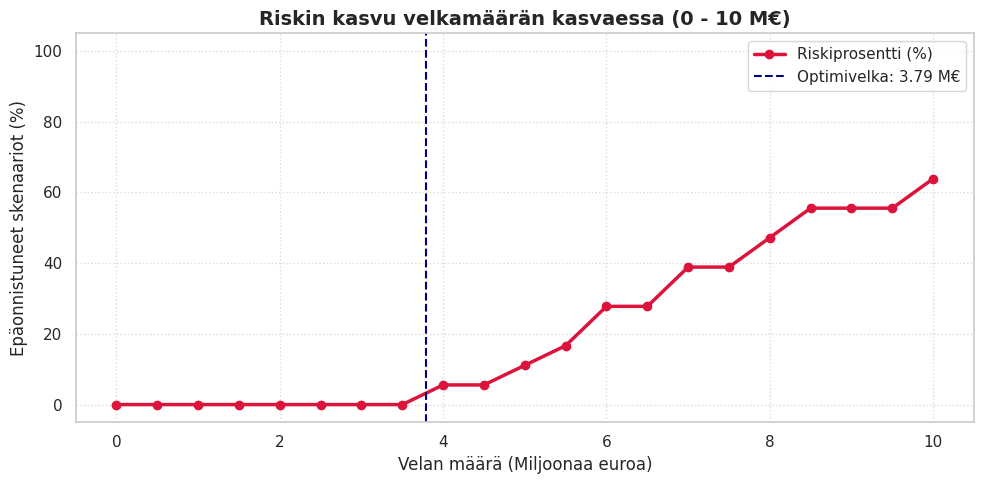

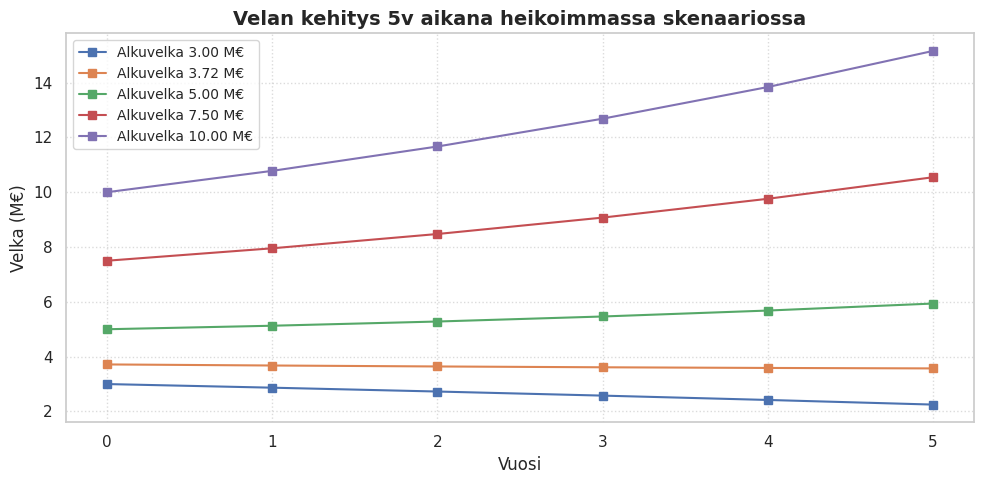

In [ ]:
# Kuvaaja 1: Riskiprofiili (Epäonnistumis-% vs Velka)
plt.figure(figsize=(10, 5))
plt.plot(df_risk['Velka (€)'] / 1e6, df_risk['Riski / Epäonnistumis-%'], marker='o', color='crimson', linewidth=2.5, label='Riskiprosentti (%)')
plt.axvline(x=opt_debt / 1e6, color='navy', linestyle='--', label=f'Optimivelka: {opt_debt/1e6:.2f} M€')
plt.title('Riskin kasvu velkamäärän kasvaessa (0 - 10 M€)', fontsize=14, fontweight='bold')
plt.xlabel('Velan määrä (Miljoonaa euroa)', fontsize=12)
plt.ylabel('Epäonnistuneet skenaariot (%)', fontsize=12)
plt.ylim(-5, 105)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Kuvaaja 2: Velan kehitys heikoimmassa skenaariossa (Vuokra 30€, Käyttöaste 65%, Korko 13%, Inflaatio 5%)
plt.figure(figsize=(10, 5))
years = list(range(6))
worst_rent, worst_occ, worst_int, worst_infl = 30, 0.65, 0.13, 0.05

for test_d in [3_000_000, 3_716_000, 5_000_000, 7_500_000, 10_000_000]:
    _, _, hist = simulate_5yr(test_d, worst_rent, worst_occ, worst_int, worst_infl)
    plt.plot(years, [h / 1e6 for h in hist], marker='s', label=f'Alkuvelka {test_d/1e6:.2f} M€')

plt.title('Velan kehitys 5v aikana heikoimmassa skenaariossa', fontsize=14, fontweight='bold')
plt.xlabel('Vuosi', fontsize=12)
plt.ylabel('Velka (M€)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

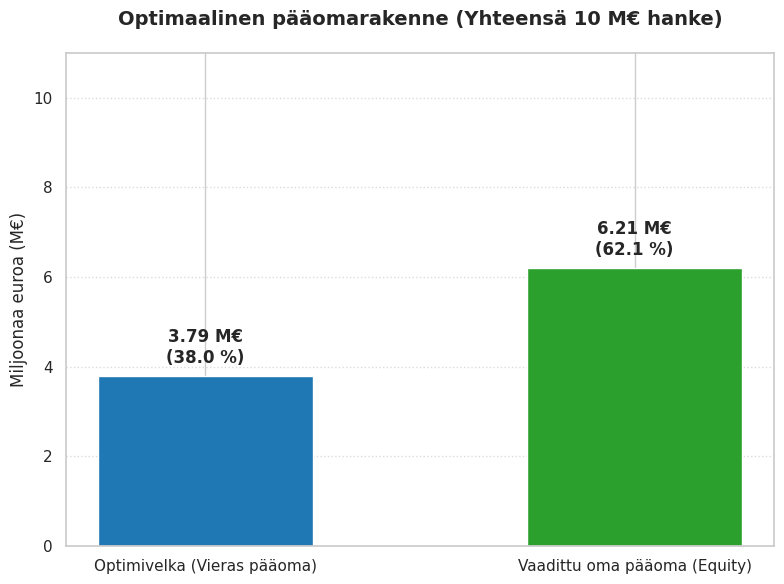

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Kuvaaja 3: Optimivelan ja vaaditun oman pääoman rakenne
fig, ax = plt.subplots(figsize=(8, 6))

categories = ['Optimivelka (Vieras pääoma)', 'Vaadittu oma pääoma (Equity)']
values = [opt_debt / 1e6, opt_equity / 1e6]
colors = ['#1f77b4', '#2ca02c']

bars = ax.bar(categories, values, color=colors, width=0.5)

# Lisätään arvot pylväiden päälle
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.2, f"{yval:.2f} M€\n({(yval/10)*100:.1f} %)", ha='center', va='bottom', fontweight='bold')

ax.set_title('Optimaalinen pääomarakenne (Yhteensä 10 M€ hanke)', fontsize=14, fontweight='bold', pad=20)
ax.set_ylabel('Miljoonaa euroa (M€)', fontsize=12)
ax.set_ylim(0, 11)
ax.grid(axis='y', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

## 8. Yhteenveto ja Päätöksentekosuositus Talousjohtajalle / Yrittäjälle

### Keskeiset tulokset:
1. **Optimaalinen velkamäärä ($D_{\text{opt}}$):** **3 716 000 €** (noin **3,72 M€** eli 37,2 % 10 M€ hankkeesta).
2. **Oman pääoman tarve:** **6 284 000 €** (noin **6,28 M€** eli 62,8 %).
3. **Riski kynnyksen jälkeen:**
   - Välillä **0 – 3,71 M€** riski on **0 %** (velka ei kasva missään 36 skenaariossa).
   - **4,0 M€** velalla epäonnistumisriski on **5,6 %** (2 skenaariota 36:sta aiheuttaa negatiivisen kassavirran).
   - **5,0 M€** velalla riski nousee **11,1 %:iin**.
   - **7,5 M€** velalla riski on jo **38,9 %**.
   - **10,0 M€** velalla (100 % vieras pääoma) peräti **63,9 % skenaarioista epäonnistuu** (velka kasvaa hallitsemattomasti).

### Suositus:
Yrittäjän kannattaa mitoittaa vieraan pääoman määrä enintään **3,72 miljoonaan euroon**, mikäli halutaan täysi varmuus siitä, ettei velkamäärä lähde kasvamaan heikoimmassakaan markkinatilanteessa (30 €/m² vuokra, 65 % käyttöaste, 13 % korko ja 5 % inflaatio).